In [1]:
!pip install pandas numpy scikit-learn

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


#**Dataset Upload**

In [4]:
#Libraries to be used
import numpy as np
import pandas as pd
import matplotlib
import sklearn

import os
import zipfile
from google.colab import files

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification

In [5]:
import os

data_path = "/content/drive/MyDrive/CIC IoMT 2024 WiFi MQTT Kaggle"

print(os.listdir(data_path))

['CIC_IoMT_2024_WiFi_MQTT_test.parquet', 'CIC_IoMT_2024_WiFi_MQTT_train.parquet']


In [6]:
import pandas as pd
from google.colab import files

# Identify the uploaded files
train_file = data_path + "/CIC_IoMT_2024_WiFi_MQTT_train.parquet"
test_file = data_path + "/CIC_IoMT_2024_WiFi_MQTT_test.parquet"

# Load datasets
train_df = pd.read_parquet(train_file)
test_df = pd.read_parquet(test_file)

In [ ]:
import pandas as pd
from google.colab import files

# Upload both Parquet files from Downloads
uploaded = files.upload()

# Identify the uploaded files
train_file = data_path + "/CIC_IoMT_2024_WiFi_MQTT_train.parquet"
test_file = data_path + "/CIC_IoMT_2024_WiFi_MQTT_test.parquet"

if train_file not in uploaded or test_file not in uploaded:
    raise FileNotFoundError("Please upload both training and testing Parquet files.")

# Load datasets
train_df = pd.read_parquet(train_file)
test_df = pd.read_parquet(test_file)

KeyboardInterrupt: 

#**Dataset Information**

In [7]:
# Display dataset information
print("\nDataset information")
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining data")
display(train_df.head())

print("\nTesting data")
display(test_df.head())

print("\nColumn names")
print(train_df.columns.tolist())

print("\nData types")
print(train_df.dtypes)

print("\nDatasets loaded successfully!")


Dataset information
Training dataset shape: (7160831, 46)
Testing dataset shape: (1614182, 46)

Training data


/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,683.500000,17.000000,64.0,553148.437500,553148.437500,0,0.0,0.0,0.0,0.000000,...,0.000000,50.00000,101635944.0,9.5,10.000000,0.000000,0.000000,0.000000,141.5,TCP_IP-DDoS-UDP2_train
1,1745.920044,16.125000,64.0,29919.544922,29919.544922,0,0.0,0.0,0.0,0.040009,...,1.569336,52.28125,84696616.0,9.5,10.046875,2.152344,11.785338,0.229980,141.5,TCP_IP-DDoS-UDP2_train
2,2830.360107,15.789062,64.0,27075.605469,27075.605469,0,0.0,0.0,0.0,0.059998,...,7.449219,53.25000,84696616.0,9.5,10.351562,10.554688,113.675461,0.529785,141.5,TCP_IP-DDoS-UDP2_train
3,4087.500000,16.890625,64.0,19660.156250,19660.156250,0,0.0,0.0,0.0,0.000000,...,0.873047,50.15625,84696616.0,9.5,10.031250,1.236328,4.490081,0.180054,141.5,TCP_IP-DDoS-UDP2_train
4,3916.000000,17.000000,64.0,270322.781250,270322.781250,0,0.0,0.0,0.0,0.000000,...,0.000000,50.00000,84696616.0,9.5,10.000000,0.000000,0.000000,0.000000,141.5,TCP_IP-DDoS-UDP2_train



Testing data


/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,2525.0,17.0,64.0,190424.250000,190424.250000,0,0.0,0.0,0.0,0.0,...,0.0,50.0,101615016.0,9.5,10.0,0.0,0.0,0.0,141.5,TCP_IP-DoS-UDP_test
1,7525.0,17.0,64.0,30811.365234,30811.365234,0,0.0,0.0,0.0,0.0,...,0.0,50.0,84679176.0,9.5,10.0,0.0,0.0,0.0,141.5,TCP_IP-DoS-UDP_test
2,7659.5,17.0,64.0,130358.820312,130358.820312,0,0.0,0.0,0.0,0.0,...,0.0,50.0,84679176.0,9.5,10.0,0.0,0.0,0.0,141.5,TCP_IP-DoS-UDP_test
3,4375.0,17.0,64.0,22628.230469,22628.230469,0,0.0,0.0,0.0,0.0,...,0.0,50.0,84679176.0,9.5,10.0,0.0,0.0,0.0,141.5,TCP_IP-DoS-UDP_test
4,9375.0,17.0,64.0,21570.292969,21570.292969,0,0.0,0.0,0.0,0.0,...,0.0,50.0,84679176.0,9.5,10.0,0.0,0.0,0.0,141.5,TCP_IP-DoS-UDP_test



Column names
['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']

Data types
Header_Length       float32
Protocol Type       float16
Duration            float16
Rate                float32
Srate               float32
Drate                  int8
fin_flag_number     float16
syn_flag_number     float16
rst_flag_number     float16
psh_flag_number     float16
ack_flag_number     float16
ece_flag_number     float16
cwr_flag_number     float16
ack_count           float16
syn_count           float16
fin_count           float16
rst_count         

#**Dataset Inspection**

In [8]:
#understand the dataset and identify target column
#checks the dataset size, columns, data types, missing values, duplicates, sample records, possible label columns


print("TRAINING SHAPE:", train_df.shape)
print("TESTING SHAPE:", test_df.shape)

print("\nCOLUMNS:")
print(train_df.columns.tolist())

print("\nDATA TYPES:")
print(train_df.dtypes)

print("\nMISSING VALUES:")
print(train_df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDUPLICATES:", train_df.duplicated().sum())

print("\nSAMPLE DATA:")
display(train_df.head())

print("\nPOSSIBLE LABEL COLUMNS:")
for col in train_df.columns:
    if any(word in col.lower() for word in ["label", "class", "attack"]):
        print(f"\n{col}:")
        print(train_df[col].value_counts().head(15))

TRAINING SHAPE: (7160831, 46)
TESTING SHAPE: (1614182, 46)

COLUMNS:
['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']

DATA TYPES:
Header_Length       float32
Protocol Type       float16
Duration            float16
Rate                float32
Srate               float32
Drate                  int8
fin_flag_number     float16
syn_flag_number     float16
rst_flag_number     float16
psh_flag_number     float16
ack_flag_number     float16
ece_flag_number     float16
cwr_flag_number     float16
ack_count           float16
syn_count         

/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,683.500000,17.000000,64.0,553148.437500,553148.437500,0,0.0,0.0,0.0,0.000000,...,0.000000,50.00000,101635944.0,9.5,10.000000,0.000000,0.000000,0.000000,141.5,TCP_IP-DDoS-UDP2_train
1,1745.920044,16.125000,64.0,29919.544922,29919.544922,0,0.0,0.0,0.0,0.040009,...,1.569336,52.28125,84696616.0,9.5,10.046875,2.152344,11.785338,0.229980,141.5,TCP_IP-DDoS-UDP2_train
2,2830.360107,15.789062,64.0,27075.605469,27075.605469,0,0.0,0.0,0.0,0.059998,...,7.449219,53.25000,84696616.0,9.5,10.351562,10.554688,113.675461,0.529785,141.5,TCP_IP-DDoS-UDP2_train
3,4087.500000,16.890625,64.0,19660.156250,19660.156250,0,0.0,0.0,0.0,0.000000,...,0.873047,50.15625,84696616.0,9.5,10.031250,1.236328,4.490081,0.180054,141.5,TCP_IP-DDoS-UDP2_train
4,3916.000000,17.000000,64.0,270322.781250,270322.781250,0,0.0,0.0,0.0,0.000000,...,0.000000,50.00000,84696616.0,9.5,10.000000,0.000000,0.000000,0.000000,141.5,TCP_IP-DDoS-UDP2_train



POSSIBLE LABEL COLUMNS:

label:
label
TCP_IP-DDoS-UDP2_train    207295
TCP_IP-DDoS-UDP3_train    206604
TCP_IP-DDoS-UDP4_train    206343
TCP_IP-DDoS-UDP1_train    206170
TCP_IP-DDoS-UDP5_train    205507
TCP_IP-DDoS-UDP8_train    204105
TCP_IP-DDoS-TCP3_train    204075
TCP_IP-DDoS-SYN2_train    203669
TCP_IP-DDoS-TCP1_train    202311
TCP_IP-DDoS-UDP6_train    202247
TCP_IP-DDoS-SYN3_train    202023
TCP_IP-DDoS-TCP4_train    200998
TCP_IP-DDoS-SYN1_train    199390
TCP_IP-DDoS-UDP7_train    197685
TCP_IP-DDoS-TCP2_train    197081
Name: count, dtype: int64


In [9]:
import pandas as pd

print("All training labels")
print(train_df["label"].value_counts().to_string())

print("\nAll testing labels")
print(test_df["label"].value_counts().to_string())

print("\nMissing Values")
print("Training:", train_df.isnull().sum().sum())
print("Testing:", test_df.isnull().sum().sum())

print("\nInfinite values")
print("Training:", np.isinf(train_df.select_dtypes(include=np.number)).sum().sum())
print("Testing:", np.isinf(test_df.select_dtypes(include=np.number)).sum().sum())

print("\nDuplicated values")
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

All training labels
label
TCP_IP-DDoS-UDP2_train           207295
TCP_IP-DDoS-UDP3_train           206604
TCP_IP-DDoS-UDP4_train           206343
TCP_IP-DDoS-UDP1_train           206170
TCP_IP-DDoS-UDP5_train           205507
TCP_IP-DDoS-UDP8_train           204105
TCP_IP-DDoS-TCP3_train           204075
TCP_IP-DDoS-SYN2_train           203669
TCP_IP-DDoS-TCP1_train           202311
TCP_IP-DDoS-UDP6_train           202247
TCP_IP-DDoS-SYN3_train           202023
TCP_IP-DDoS-TCP4_train           200998
TCP_IP-DDoS-SYN1_train           199390
TCP_IP-DDoS-UDP7_train           197685
TCP_IP-DDoS-TCP2_train           197081
TCP_IP-DDoS-SYN4_train           196880
TCP_IP-DDoS-ICMP5_train          195032
TCP_IP-DDoS-ICMP1_train          194938
TCP_IP-DDoS-ICMP2_train          194818
TCP_IP-DDoS-ICMP8_train          193340
TCP_IP-DDoS-ICMP4_train          192741
Benign_train                     192732
TCP_IP-DDoS-ICMP6_train          190875
TCP_IP-DDoS-ICMP3_train          189710
TCP_IP-DDoS-IC

#**Data Preprocessing**

In [10]:
#contains both benign and malicious traffic → use binary intrusion-detection

# Separate features from labels
X_train = train_df.drop(columns=["label"]).astype("float32")
X_test = test_df.drop(columns=["label"]).astype("float32")

# Convert labels to Benign = 0, Attack = 1
y_train = (train_df["label"].astype(str).str.startswith("Benign") == False).astype("int8")
y_test = (test_df["label"].astype(str).str.startswith("Benign") == False).astype("int8")

# Results
print("Feature data")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nBinary label distribution")
print("Training:")
print(y_train.value_counts().rename(index={0: "Benign (0)", 1: "Attack (1)"}))

print("\nTesting:")
print(y_test.value_counts().rename(index={0: "Benign (0)", 1: "Attack (1)"}))

print("\nClass precentages")
print("Training:")
print((y_train.value_counts(normalize=True) * 100).rename(index={0: "Benign (0)", 1: "Attack (1)"}))

print("\nTesting:")
print((y_test.value_counts(normalize=True) * 100).rename(index={0: "Benign (0)", 1: "Attack (1)"}))

Feature data
X_train: (7160831, 45)
X_test: (1614182, 45)

Binary label distribution
Training:
label
Attack (1)    6968099
Benign (0)     192732
Name: count, dtype: int64

Testing:
label
Attack (1)    1576575
Benign (0)      37607
Name: count, dtype: int64

Class precentages
Training:
label
Attack (1)    97.308525
Benign (0)     2.691475
Name: proportion, dtype: float64

Testing:
label
Attack (1)    97.670213
Benign (0)     2.329787
Name: proportion, dtype: float64


In [11]:
#dataset is very imbalanced so we will check if the reason is the duplicated raws or not

# Hash training features in chunks to reduce memory usage
chunk_size = 100_000
train_hashes = []

print("Hashing training data...")

for start in range(0, len(X_train), chunk_size):
    chunk = X_train.iloc[start:start + chunk_size]
    hashes = pd.util.hash_pandas_object(chunk, index=False).to_numpy()
    train_hashes.append(hashes)

train_hashes = np.concatenate(train_hashes)
train_hashes.sort()

print("Training data hashed.")

# Count unique training feature records
unique_train = np.unique(train_hashes).size

# Check testing records against training records
overlap_count = 0
test_hashes_all = []

print("Checking testing data...")

for start in range(0, len(X_test), chunk_size):
    chunk = X_test.iloc[start:start + chunk_size]
    hashes = pd.util.hash_pandas_object(chunk, index=False).to_numpy()

    positions = np.searchsorted(train_hashes, hashes)
    valid = positions < len(train_hashes)

    matches = np.zeros(len(hashes), dtype=bool)
    matches[valid] = (
        train_hashes[positions[valid]] == hashes[valid]
    )

    overlap_count += matches.sum()
    test_hashes_all.append(hashes)

test_hashes_all = np.concatenate(test_hashes_all)
unique_test = np.unique(test_hashes_all).size

print("\nDuplicate overlap results")
print("Training records:", len(X_train))
print("Unique training feature records:", unique_train)
print("Testing records:", len(X_test))
print("Unique testing feature records:", unique_test)
print("Testing records also found in training:", overlap_count)
print("Overlap percentage:", round(overlap_count / len(X_test) * 100, 2), "%")

Hashing training data...
Training data hashed.
Checking testing data...

Duplicate overlap results
Training records: 7160831
Unique training feature records: 4515078
Testing records: 1614182
Unique testing feature records: 892266
Testing records also found in training: 13533
Overlap percentage: 0.84 %


In [12]:
#Prepare the data for the baseline models, by checking the features quality

# Feature statistics
feature_stats = pd.DataFrame({
    "Minimum": X_train.min(),
    "Maximum": X_train.max(),
    "Mean": X_train.mean(),
    "Standard Deviation": X_train.std(),
    "Unique Values": X_train.nunique()
})

# Identifying constant features
constant_features = feature_stats[
    feature_stats["Unique Values"] <= 1
]

print("Feature quality check:")
print("Total features:", X_train.shape[1])
print("Constant features:", len(constant_features))

if len(constant_features) > 0:
    display(constant_features)
else:
    print("No constant features found.")

print("\nFinal feature statistics")
display(feature_stats)

Feature quality check:
Total features: 45
Constant features: 1


,Minimum,Maximum,Mean,Standard Deviation,Unique Values
Drate,0.0,0.0,0.0,0.0,1



Final feature statistics


,Minimum,Maximum,Mean,Standard Deviation,Unique Values
Header_Length,0.000000,9.895636e+06,2.958836e+04,2.756842e+05,822146
Protocol Type,0.000000,1.700000e+01,8.043002e+00,6.196044e+00,1441
Duration,0.000000,2.550000e+02,6.474657e+01,8.384166e+00,2684
Rate,0.000000,2.097152e+06,1.523202e+04,3.806764e+04,4174510
Srate,0.000000,2.097152e+06,1.523202e+04,3.806764e+04,4174510
Drate,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1
fin_flag_number,0.000000,1.000000e+00,5.079653e-03,3.385478e-02,229
syn_flag_number,0.000000,1.000000e+00,1.587621e-01,3.278855e-01,525
rst_flag_number,0.000000,1.000000e+00,3.862118e-02,1.334433e-01,501
psh_flag_number,0.000000,1.000000e+00,2.240627e-02,9.554674e-02,428


In [13]:
from sklearn.preprocessing import StandardScaler

# remove the constant zero valued feature Drate
X_train = X_train.drop(columns=["Drate"])
X_test = X_test.drop(columns=["Drate"])

# random forest data → unscaled data
X_train_rf = X_train.copy()
X_test_rf = X_test.copy()

# logistic regression data → standardization/scaling the data
scaler = StandardScaler()

X_train_lr = scaler.fit_transform(X_train)
X_test_lr = scaler.transform(X_test)

# check the prepared datasets
print("Model data perparation")

print("\nRandom Forest:")
print("Training:", X_train_rf.shape)
print("Testing:", X_test_rf.shape)

print("\nLogistic Regression:")
print("Training:", X_train_lr.shape)
print("Testing:", X_test_lr.shape)

print("\nRemaining features:", X_train.shape[1])
print("Removed features: Drate")

print("\nPreparation completed successfully!")

Model data perparation

Random Forest:
Training: (7160831, 44)
Testing: (1614182, 44)

Logistic Regression:
Training: (7160831, 44)
Testing: (1614182, 44)

Remaining features: 44
Removed features: Drate

Preparation completed successfully!


In [14]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# create a stratified traning sample
sample_size = 300_000

train_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=sample_size,
    stratify=y_train,
    random_state=42
)

# same records for both models
X_rf_sample = X_train_rf.iloc[train_indices]
X_lr_sample = X_train_lr[train_indices]

y_sample = y_train.iloc[train_indices]

print("Training sample:", X_rf_sample.shape)
print("\nSample class distribution:")
print(y_sample.value_counts())


# define the models
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=3,
    min_samples_leaf=2
)

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=300,
    random_state=42,
)


# train random forest
print("\nTraining Random Forest...")

rf_model.fit(X_rf_sample, y_sample)

print("Random Forest training completed!")


# train logistic regression
print("\nTraining Logistic Regression...")

lr_model.fit(X_lr_sample, y_sample)

print("Logistic Regression training completed!")


# evaluate models
def evaluate_model(model, X_test_data, y_test_data, model_name):

    predictions = []
    chunk_size = 100_000

    for start in range(0, len(y_test_data), chunk_size):

        end = start + chunk_size

        X_chunk = (
            X_test_data.iloc[start:end]
            if isinstance(X_test_data, pd.DataFrame)
            else X_test_data[start:end]
        )

        predictions.extend(model.predict(X_chunk))

    predictions = np.array(predictions)

    accuracy = accuracy_score(y_test_data, predictions)
    precision = precision_score(y_test_data, predictions)
    recall = recall_score(y_test_data, predictions)
    f1 = f1_score(y_test_data, predictions)

    tn, fp, fn, tp = confusion_matrix(
        y_test_data, predictions, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    print(f"\n{model_name} RESULTS")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("False Positive Rate:", round(fpr, 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_data, predictions, labels=[0, 1]))

    print("\nClassification Report:")
    print(classification_report(
        y_test_data,
        predictions,
        labels=[0, 1],
        target_names=["Benign", "Attack"]
    ))

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "False Positive Rate": fpr
    }


# 6. EVALUATE RF
rf_results = evaluate_model(
    rf_model,
    X_test_rf,
    y_test,
    "Random Forest"
)


# 7. EVALUATE LR
lr_results = evaluate_model(
    lr_model,
    X_test_lr,
    y_test,
    "Logistic Regression"
)

# Compare baseline resutles
baseline_results = pd.DataFrame([
    rf_results,
    lr_results
])

print("\nBaseline model comparison")
display(baseline_results)

Training sample: (300000, 44)

Sample class distribution:
label
1    291926
0      8074
Name: count, dtype: int64

Training Random Forest...
Random Forest training completed!

Training Logistic Regression...
Logistic Regression training completed!

Random Forest RESULTS
Accuracy: 0.9983
Precision: 0.9993
Recall: 0.9989
F1-score: 0.9991
False Positive Rate: 0.0297

Confusion Matrix:
[[  36490    1117]
 [   1682 1574893]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.97      0.96     37607
      Attack       1.00      1.00      1.00   1576575

    accuracy                           1.00   1614182
   macro avg       0.98      0.98      0.98   1614182
weighted avg       1.00      1.00      1.00   1614182


Logistic Regression RESULTS
Accuracy: 0.9859
Precision: 0.9999
Recall: 0.9856
F1-score: 0.9927
False Positive Rate: 0.0045

Confusion Matrix:
[[  37437     170]
 [  22632 1553943]]

Classification Report:
              preci

,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate
0,Random Forest,0.998266,0.999291,0.998933,0.999112,0.029702
1,Logistic Regression,0.985874,0.999891,0.985645,0.992717,0.004520


In [15]:
#Creating the poisoned datasets

# Original clean labels
y_clean = np.asarray(y_sample).copy()

# Poisoning percentages 5%, 10%, 20%, and 30%
poisoning_rates = [0.05, 0.10, 0.20, 0.30]

# Generating one random order
rng = np.random.default_rng(42)
random_order = rng.permutation(len(y_clean))

# Store poisoned datasets and flipped indices
poisoned_datasets = {}
flipped_indices = {}

for rate in poisoning_rates:

    # Number of labels to flip
    n_flip = int(len(y_clean) * rate)

    # Select records to poison
    selected_positions = random_order[:n_flip]

    # Start from clean labels every time
    y_poisoned = y_clean.copy()

    # Flip labels: 0 becomes 1, and 1 becomes 0
    y_poisoned[selected_positions] = 1 - y_poisoned[selected_positions]

    # Store results
    rate_name = f"{int(rate * 100)}%"

    poisoned_datasets[rate_name] = pd.Series(y_poisoned)
    flipped_indices[rate_name] = selected_positions

    print(f"\nPoisoning rate: {rate_name}")
    print("Labels flipped:", n_flip)
    print("New class distribution:")
    print(pd.Series(y_poisoned).value_counts().sort_index())

print("\nAll four poisoned datasets created successfully!")


Poisoning rate: 5%
Labels flipped: 15000
New class distribution:
0     22288
1    277712
Name: count, dtype: int64

Poisoning rate: 10%
Labels flipped: 30000
New class distribution:
0     36480
1    263520
Name: count, dtype: int64

Poisoning rate: 20%
Labels flipped: 60000
New class distribution:
0     64846
1    235154
Name: count, dtype: int64

Poisoning rate: 30%
Labels flipped: 90000
New class distribution:
0     93148
1    206852
Name: count, dtype: int64

All four poisoned datasets created successfully!


In [16]:
#so the poisoned labels won't get lost and indices when the Colab runtime resets

# Save poisoned labels and flipped positions
save_data = {}

for rate in poisoned_datasets:
    save_data[f"labels_{rate}"] = poisoned_datasets[rate].to_numpy()
    save_data[f"indices_{rate}"] = flipped_indices[rate]

# Save original training dataset positions too
for rate in flipped_indices:
    save_data[f"original_indices_{rate}"] = train_indices[
        flipped_indices[rate]
    ]

np.savez_compressed(
    "/content/poisoned_datasets.npz",
    **save_data
)

print("Poisoned datasets and indices saved successfully!")

Poisoned datasets and indices saved successfully!


#**Evaluate poisoned-model**

In [17]:
#Training


from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Store trained models
poisoned_models = {}

for rate, y_poisoned in poisoned_datasets.items():

    print(f"\nTraining models with {rate} label flipping...")

    # Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=3,
        min_samples_leaf=2
    )

    rf.fit(X_rf_sample, y_poisoned)

    # Logistic Regression
    lr = LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        random_state=42,
    )

    lr.fit(X_lr_sample, y_poisoned)

    # Save models
    poisoned_models[rate] = {
        "Random Forest": rf,
        "Logistic Regression": lr
    }

    print(f"{rate} models trained successfully!")

print("\nAll poisoned models trained!")


Training models with 5% label flipping...
5% models trained successfully!

Training models with 10% label flipping...
10% models trained successfully!

Training models with 20% label flipping...
20% models trained successfully!

Training models with 30% label flipping...
30% models trained successfully!

All poisoned models trained!


In [18]:
#evaluating the models with the org test dataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

attack_results = []

def predict_in_chunks(model, X, chunk_size=100000):

    predictions = np.empty(len(X), dtype=np.int8)

    for start in range(0, len(X), chunk_size):
        end = min(start + chunk_size, len(X))

        if isinstance(X, pd.DataFrame):
            X_chunk = X.iloc[start:end]
        else:
            X_chunk = X[start:end]

        predictions[start:end] = model.predict(X_chunk)

    return predictions


for rate, models in poisoned_models.items():

    for model_name, model in models.items():

        print(f"\nEvaluating {model_name} - {rate} poisoning...")

        # Select the correct test features
        if model_name == "Random Forest":
            X_eval = X_test_rf
        else:
            X_eval = X_test_lr

        # Predict on untouched test data
        predictions = predict_in_chunks(model, X_eval)

        # Calculate metrics
        accuracy = accuracy_score(y_test, predictions)
        precision = precision_score(y_test, predictions, zero_division=0)
        recall = recall_score(y_test, predictions, zero_division=0)
        f1 = f1_score(y_test, predictions, zero_division=0)

        tn, fp, fn, tp = confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ).ravel()

        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        # Store results
        attack_results.append({
            "Poisoning Rate": rate,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1,
            "False Positive Rate": fpr
        })

        print("Accuracy:", round(accuracy, 4))
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-score:", round(f1, 4))
        print("False Positive Rate:", round(fpr, 4))


# Display final comparison
attack_results_df = pd.DataFrame(attack_results)

display(
    attack_results_df.round(4)
)


Evaluating Random Forest - 5% poisoning...
Accuracy: 0.9933
Precision: 0.9991
Recall: 0.9941
F1-score: 0.9966
False Positive Rate: 0.0389

Evaluating Logistic Regression - 5% poisoning...
Accuracy: 0.9614
Precision: 1.0
Recall: 0.9606
F1-score: 0.9799
False Positive Rate: 0.0016

Evaluating Random Forest - 10% poisoning...
Accuracy: 0.9575
Precision: 0.9991
Recall: 0.9573
F1-score: 0.9778
False Positive Rate: 0.0356

Evaluating Logistic Regression - 10% poisoning...
Accuracy: 0.948
Precision: 0.9999
Recall: 0.9469
F1-score: 0.9727
False Positive Rate: 0.0037

Evaluating Random Forest - 20% poisoning...
Accuracy: 0.887
Precision: 0.9989
Recall: 0.8853
F1-score: 0.9387
False Positive Rate: 0.0425

Evaluating Logistic Regression - 20% poisoning...
Accuracy: 0.9273
Precision: 0.9988
Recall: 0.9267
F1-score: 0.9614
False Positive Rate: 0.0465

Evaluating Random Forest - 30% poisoning...
Accuracy: 0.7528
Precision: 0.998
Recall: 0.7485
F1-score: 0.8554
False Positive Rate: 0.0639

Evaluatin

,Poisoning Rate,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate
0,5%,Random Forest,0.9933,0.9991,0.9941,0.9966,0.0389
1,5%,Logistic Regression,0.9614,1.0000,0.9606,0.9799,0.0016
2,10%,Random Forest,0.9575,0.9991,0.9573,0.9778,0.0356
3,10%,Logistic Regression,0.9480,0.9999,0.9469,0.9727,0.0037
4,20%,Random Forest,0.8870,0.9989,0.8853,0.9387,0.0425
5,20%,Logistic Regression,0.9273,0.9988,0.9267,0.9614,0.0465
6,30%,Random Forest,0.7528,0.9980,0.7485,0.8554,0.0639
7,30%,Logistic Regression,0.9189,0.9991,0.9178,0.9567,0.0350


#**Generate Out-of-Fold (OOF) Predictions**

In [19]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold


def generate_oof_predictions(X_train, y_train_poisoned, model):

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    oof_predictions = np.empty(len(y_train_poisoned), dtype=int)

    oof_probabilities = np.zeros(
        (len(y_train_poisoned), 2),
        dtype=float
    )

    for fold, (train_indices, validation_indices) in enumerate(
        skf.split(X_train, y_train_poisoned)
    ):

        print(f"\nProcessing Fold {fold + 1}/5")

        if isinstance(X_train, pd.DataFrame):
            X_fold_train = X_train.iloc[train_indices]
            X_fold_validation = X_train.iloc[validation_indices]
        else:
            X_fold_train = X_train[train_indices]
            X_fold_validation = X_train[validation_indices]

        if isinstance(y_train_poisoned, (pd.Series, pd.DataFrame)):
            y_fold_train = y_train_poisoned.iloc[train_indices]
        else:
            y_fold_train = y_train_poisoned[train_indices]

        fold_model = clone(model)

        fold_model.fit(X_fold_train, y_fold_train)

        predictions = fold_model.predict(X_fold_validation)

        probabilities = fold_model.predict_proba(X_fold_validation)

        oof_predictions[validation_indices] = predictions
        oof_probabilities[validation_indices] = probabilities

        print(f"Fold {fold + 1} completed")

    print("\nOOF predictions completed successfully!")

    return oof_predictions, oof_probabilities


# Generate OOF predictions for Random forest

poisoning_rates = ["5%", "10%", "20%", "30%"]

rf_oof_results = {}

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"RANDOM FOREST OOF GENERATION: {rate} POISONING")
    print("=" * 50)

    y_poisoned = poisoned_datasets[rate]

    predictions, probabilities = generate_oof_predictions(
        X_rf_sample,
        y_poisoned,
        rf_model
    )

    rf_oof_results[rate] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    print("Predictions shape:", predictions.shape)
    print("Probabilities shape:", probabilities.shape)

  # Generate OOF predictions for Logistic Regression

lr_oof_results = {}

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"LOGISTIC REGRESSION OOF GENERATION: {rate} POISONING")
    print("=" * 50)

    y_poisoned = poisoned_datasets[rate]

    predictions, probabilities = generate_oof_predictions(
        X_lr_sample,
        y_poisoned,
        lr_model
    )

    lr_oof_results[rate] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    print("Predictions shape:", predictions.shape)
    print("Probabilities shape:", probabilities.shape)


RANDOM FOREST OOF GENERATION: 5% POISONING

Processing Fold 1/5
Fold 1 completed

Processing Fold 2/5
Fold 2 completed

Processing Fold 3/5
Fold 3 completed

Processing Fold 4/5
Fold 4 completed

Processing Fold 5/5
Fold 5 completed

OOF predictions completed successfully!
Predictions shape: (300000,)
Probabilities shape: (300000, 2)

RANDOM FOREST OOF GENERATION: 10% POISONING

Processing Fold 1/5
Fold 1 completed

Processing Fold 2/5
Fold 2 completed

Processing Fold 3/5
Fold 3 completed

Processing Fold 4/5
Fold 4 completed

Processing Fold 5/5
Fold 5 completed

OOF predictions completed successfully!
Predictions shape: (300000,)
Probabilities shape: (300000, 2)

RANDOM FOREST OOF GENERATION: 20% POISONING

Processing Fold 1/5
Fold 1 completed

Processing Fold 2/5
Fold 2 completed

Processing Fold 3/5
Fold 3 completed

Processing Fold 4/5
Fold 4 completed

Processing Fold 5/5
Fold 5 completed

OOF predictions completed successfully!
Predictions shape: (300000,)
Probabilities shape:

#**Calculate Prediction Confidence**

In [20]:
def calculate_prediction_confidence(oof_probabilities):

    confidence = np.max(oof_probabilities, axis=1)

    return confidence


# Calculate confidence for Random Forest

rf_confidence_results = {}

for rate in poisoning_rates:

    probabilities = rf_oof_results[rate]["probabilities"]

    confidence = calculate_prediction_confidence(probabilities)

    rf_confidence_results[rate] = confidence

    print(f"\nPoisoning Rate: {rate}")
    print("Average confidence:", round(confidence.mean(), 4))
    print("Minimum confidence:", round(confidence.min(), 4))
    print("Maximum confidence:", round(confidence.max(), 4))

    print("\nFirst 10 confidence scores:")
    print(confidence[:10])

  # Calculate confidence for Logistic Regression

lr_confidence_results = {}

for rate in poisoning_rates:

    probabilities = lr_oof_results[rate]["probabilities"]

    confidence = calculate_prediction_confidence(probabilities)

    lr_confidence_results[rate] = confidence

    print(f"\nPoisoning Rate: {rate}")
    print("Average confidence:", round(confidence.mean(), 4))
    print("Minimum confidence:", round(confidence.min(), 4))
    print("Maximum confidence:", round(confidence.max(), 4))

    print("\nFirst 10 confidence scores:")
    print(confidence[:10])


Poisoning Rate: 5%
Average confidence: 0.7975
Minimum confidence: 0.5
Maximum confidence: 1.0

First 10 confidence scores:
[0.8871469  0.52673511 0.86432176 0.60255261 0.92506413 0.95871842
 0.81832017 0.83248654 0.78160773 0.76807616]

Poisoning Rate: 10%
Average confidence: 0.734
Minimum confidence: 0.5
Maximum confidence: 1.0

First 10 confidence scores:
[0.52667312 0.72614994 0.84694887 0.73083699 0.71887816 0.86242551
 0.59482339 0.8377993  0.69761728 0.70475334]

Poisoning Rate: 20%
Average confidence: 0.6585
Minimum confidence: 0.5
Maximum confidence: 0.9973

First 10 confidence scores:
[0.82332678 0.60946752 0.51441496 0.67693737 0.65330341 0.59586507
 0.56392295 0.68613513 0.65749033 0.50930439]

Poisoning Rate: 30%
Average confidence: 0.6147
Minimum confidence: 0.5
Maximum confidence: 0.9858

First 10 confidence scores:
[0.53804094 0.54847085 0.74033167 0.59594587 0.65780113 0.55345943
 0.52776917 0.66177979 0.70384007 0.53567732]

Poisoning Rate: 5%
Average confidence: 0.61

#**Identify Suspicious Records**

In [21]:
def identify_suspicious_records(
    y_train_poisoned,
    oof_predictions,
    confidence,
    threshold=0.80
):

    if hasattr(y_train_poisoned, "to_numpy"):
        stored_labels = y_train_poisoned.to_numpy()
    else:
        stored_labels = np.asarray(y_train_poisoned)

    label_disagreement = stored_labels != oof_predictions

    high_confidence = confidence >= threshold

    suspicious_mask = label_disagreement & high_confidence

    suspicious_indices = np.where(suspicious_mask)[0]

    print("\nSuspicious Records Detection")
    print("Total training records:", len(stored_labels))
    print("Label disagreements:", label_disagreement.sum())
    print("High-confidence records:", high_confidence.sum())
    print("Suspicious records:", len(suspicious_indices))
    print("Confidence threshold:", threshold)

    return suspicious_indices


# Identify suspicious records for Random Forest

rf_suspicious_results = {}

confidence_threshold = 0.80

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"RANDOM FOREST SUSPICIOUS RECORD DETECTION: {rate}")
    print("=" * 50)

    suspicious_indices = identify_suspicious_records(
        poisoned_datasets[rate],
        rf_oof_results[rate]["predictions"],
        rf_confidence_results[rate],
        threshold=confidence_threshold
    )

    rf_suspicious_results[rate] = suspicious_indices

  # Identify suspicious records for Logistic Regression

lr_suspicious_results = {}

confidence_threshold = 0.80

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"LOGISTIC REGRESSION SUSPICIOUS DETECTION: {rate}")
    print("=" * 50)

    suspicious_indices = identify_suspicious_records(
        poisoned_datasets[rate],
        lr_oof_results[rate]["predictions"],
        lr_confidence_results[rate],
        threshold=confidence_threshold
    )

    lr_suspicious_results[rate] = suspicious_indices


RANDOM FOREST SUSPICIOUS RECORD DETECTION: 5%

Suspicious Records Detection
Total training records: 300000
Label disagreements: 20607
High-confidence records: 154969
Suspicious records: 7883
Confidence threshold: 0.8

RANDOM FOREST SUSPICIOUS RECORD DETECTION: 10%

Suspicious Records Detection
Total training records: 300000
Label disagreements: 41812
High-confidence records: 93010
Suspicious records: 9319
Confidence threshold: 0.8

RANDOM FOREST SUSPICIOUS RECORD DETECTION: 20%

Suspicious Records Detection
Total training records: 300000
Label disagreements: 80502
High-confidence records: 33231
Suspicious records: 6696
Confidence threshold: 0.8

RANDOM FOREST SUSPICIOUS RECORD DETECTION: 30%

Suspicious Records Detection
Total training records: 300000
Label disagreements: 114002
High-confidence records: 10443
Suspicious records: 3195
Confidence threshold: 0.8

LOGISTIC REGRESSION SUSPICIOUS DETECTION: 5%

Suspicious Records Detection
Total training records: 300000
Label disagreements:

#**Remove Suspicious Records**

In [22]:
def remove_suspicious_records(
    X_train,
    y_train_poisoned,
    suspicious_indices
):

    keep_mask = np.ones(len(y_train_poisoned), dtype=bool)

    keep_mask[suspicious_indices] = False

    if hasattr(X_train, "iloc"):
        X_train_defended = X_train.iloc[keep_mask].reset_index(drop=True)
    else:
        X_train_defended = X_train[keep_mask]

    if hasattr(y_train_poisoned, "iloc"):
        y_train_defended = y_train_poisoned.iloc[keep_mask].reset_index(drop=True)
    else:
        y_train_defended = y_train_poisoned[keep_mask]

    print("\nDefense Results")
    print("Original records:", len(keep_mask))
    print("Removed records:", len(suspicious_indices))
    print("Remaining records:", len(y_train_defended))

    return X_train_defended, y_train_defended


# Remove suspicious records for Random Forest

rf_defended_datasets = {}

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"RANDOM FOREST RECORD REMOVAL: {rate}")
    print("=" * 50)

    X_defended, y_defended = remove_suspicious_records(
        X_rf_sample,
        poisoned_datasets[rate],
        rf_suspicious_results[rate]
    )

    rf_defended_datasets[rate] = {
        "X": X_defended,
        "y": y_defended
    }

  # Remove suspicious records for Logistic Regression

lr_defended_datasets = {}

for rate in poisoning_rates:

    print("\n" + "=" * 50)
    print(f"LOGISTIC REGRESSION RECORD REMOVAL: {rate}")
    print("=" * 50)

    X_defended, y_defended = remove_suspicious_records(
        X_lr_sample,
        poisoned_datasets[rate],
        lr_suspicious_results[rate]
    )

    lr_defended_datasets[rate] = {
        "X": X_defended,
        "y": y_defended
    }


RANDOM FOREST RECORD REMOVAL: 5%

Defense Results
Original records: 300000
Removed records: 7883
Remaining records: 292117

RANDOM FOREST RECORD REMOVAL: 10%

Defense Results
Original records: 300000
Removed records: 9319
Remaining records: 290681

RANDOM FOREST RECORD REMOVAL: 20%

Defense Results
Original records: 300000
Removed records: 6696
Remaining records: 293304

RANDOM FOREST RECORD REMOVAL: 30%

Defense Results
Original records: 300000
Removed records: 3195
Remaining records: 296805

LOGISTIC REGRESSION RECORD REMOVAL: 5%

Defense Results
Original records: 300000
Removed records: 2812
Remaining records: 297188

LOGISTIC REGRESSION RECORD REMOVAL: 10%

Defense Results
Original records: 300000
Removed records: 2582
Remaining records: 297418

LOGISTIC REGRESSION RECORD REMOVAL: 20%

Defense Results
Original records: 300000
Removed records: 1868
Remaining records: 298132

LOGISTIC REGRESSION RECORD REMOVAL: 30%

Defense Results
Original records: 300000
Removed records: 855
Remai

#**Retrain the Models**

In [23]:
from sklearn.base import clone

rf_defended_models = {}

for rate in poisoning_rates:

    print(f"\nTraining defended Random Forest for {rate} poisoning...")

    X_defended = rf_defended_datasets[rate]["X"]
    y_defended = rf_defended_datasets[rate]["y"]

    # Create a fresh copy of the original Random Forest
    defended_model = clone(rf_model)

    # Train using the cleaned dataset
    defended_model.fit(X_defended, y_defended)

    rf_defended_models[rate] = defended_model

    print(f"Training completed for {rate}")
    print(f"Training records: {len(y_defended)}")


lr_defended_models = {}

for rate in poisoning_rates:

    print(f"\nTraining defended Logistic Regression for {rate} poisoning...")

    X_defended = lr_defended_datasets[rate]["X"]
    y_defended = lr_defended_datasets[rate]["y"]

    # Create a fresh copy of the original Logistic Regression
    defended_model = clone(lr_model)

    # Train using the cleaned dataset
    defended_model.fit(X_defended, y_defended)

    lr_defended_models[rate] = defended_model

    print(f"Training completed for {rate}")
    print("Training records:", len(y_defended))


Training defended Random Forest for 5% poisoning...
Training completed for 5%
Training records: 292117

Training defended Random Forest for 10% poisoning...
Training completed for 10%
Training records: 290681

Training defended Random Forest for 20% poisoning...
Training completed for 20%
Training records: 293304

Training defended Random Forest for 30% poisoning...
Training completed for 30%
Training records: 296805

Training defended Logistic Regression for 5% poisoning...
Training completed for 5%
Training records: 297188

Training defended Logistic Regression for 10% poisoning...
Training completed for 10%
Training records: 297418

Training defended Logistic Regression for 20% poisoning...
Training completed for 20%
Training records: 298132

Training defended Logistic Regression for 30% poisoning...
Training completed for 30%
Training records: 299145


#**Evaluate the Defended Models**

**Cell 1**

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_defended_model(model, X_test, y_test):

    # Predict using the untouched testing data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Calculate False Positive Rate
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "False Positive Rate": fpr
    }

**Cell 2**

In [25]:
# Evaluate defended Logistic Regression

rf_defended_results = []

for rate in poisoning_rates:

    print(f"\nEvaluating defended Random Forest for {rate} poisoning...")

    model = rf_defended_models[rate]

    metrics = evaluate_defended_model(
        model,
        X_test_rf,
        y_test
    )

    metrics["Poisoning Rate"] = rate
    metrics["Model"] = "Random Forest"

    rf_defended_results.append(metrics)

rf_defended_results_df = pd.DataFrame(rf_defended_results)

rf_defended_results_df = rf_defended_results_df[
    [
        "Poisoning Rate",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "False Positive Rate"
    ]
]

display(rf_defended_results_df)


 # Evaluate defended Logistic Regression

lr_defended_results = []

for rate in poisoning_rates:

    print(f"\nEvaluating defended Logistic Regression for {rate} poisoning...")

    model = lr_defended_models[rate]

    metrics = evaluate_defended_model(
        model,
        X_test_lr,
        y_test
    )

    metrics["Poisoning Rate"] = rate
    metrics["Model"] = "Logistic Regression"

    lr_defended_results.append(metrics)


lr_defended_results_df = pd.DataFrame(lr_defended_results)

lr_defended_results_df = lr_defended_results_df[
    [
        "Poisoning Rate",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "False Positive Rate"
    ]
]

display(lr_defended_results_df)


Evaluating defended Random Forest for 5% poisoning...

Evaluating defended Random Forest for 10% poisoning...

Evaluating defended Random Forest for 20% poisoning...

Evaluating defended Random Forest for 30% poisoning...


,Poisoning Rate,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate
0,5%,Random Forest,0.968308,0.999450,0.968085,0.983517,0.022336
1,10%,Random Forest,0.938406,0.999334,0.937561,0.967463,0.026192
2,20%,Random Forest,0.846637,0.999215,0.843641,0.914861,0.027787
3,30%,Random Forest,0.751336,0.998115,0.746815,0.854369,0.059138



Evaluating defended Logistic Regression for 5% poisoning...

Evaluating defended Logistic Regression for 10% poisoning...

Evaluating defended Logistic Regression for 20% poisoning...

Evaluating defended Logistic Regression for 30% poisoning...


,Poisoning Rate,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate
0,5%,Logistic Regression,0.977815,0.999981,0.977305,0.988513,0.000798
1,10%,Logistic Regression,0.972893,0.999956,0.972289,0.985929,0.001782
2,20%,Logistic Regression,0.960482,0.999912,0.959624,0.979354,0.003537
3,30%,Logistic Regression,0.931037,0.998359,0.930922,0.963462,0.064164


#**Evaluate Poisoning Detection**

In [26]:
# Calculate Random Forest detection performance

rf_detection_results = []

for rate in poisoning_rates:

    # Actual records that were flipped by Mai Mudathir
    true_flipped_indices = np.asarray(flipped_indices[rate])

    # Records identified by PoisonGuard
    detected_indices = np.asarray(rf_suspicious_results[rate])

    # Find records that were correctly detected
    correctly_detected = np.intersect1d(
        detected_indices,
        true_flipped_indices
    )

    # Calculate detection rate
    detection_rate = (
        len(correctly_detected) / len(true_flipped_indices)
        if len(true_flipped_indices) > 0 else 0
    )

    # Calculate detection precision
    detection_precision = (
        len(correctly_detected) / len(detected_indices)
        if len(detected_indices) > 0 else 0
    )

    rf_detection_results.append({
        "Poisoning Rate": rate,
        "Actual Flipped Records": len(true_flipped_indices),
        "Detected Suspicious Records": len(detected_indices),
        "Correctly Detected Records": len(correctly_detected),
        "Detection Rate": detection_rate,
        "Detection Precision": detection_precision
    })

rf_detection_results_df = pd.DataFrame(rf_detection_results)

display(rf_detection_results_df)

# Calculate Logistic Regression detection performance

lr_detection_results = []

for rate in poisoning_rates:

    # Actual records that were flipped by Mai Mudathir
    true_flipped_indices = np.asarray(flipped_indices[rate])

    # Records identified by PoisonGuard
    detected_indices = np.asarray(lr_suspicious_results[rate])

    # Find records that were correctly detected
    correctly_detected = np.intersect1d(
        detected_indices,
        true_flipped_indices
    )

    # Calculate detection rate
    detection_rate = (
        len(correctly_detected) / len(true_flipped_indices)
        if len(true_flipped_indices) > 0 else 0
    )

    # Calculate detection precision
    detection_precision = (
        len(correctly_detected) / len(detected_indices)
        if len(detected_indices) > 0 else 0
    )

    lr_detection_results.append({
        "Poisoning Rate": rate,
        "Actual Flipped Records": len(true_flipped_indices),
        "Detected Suspicious Records": len(detected_indices),
        "Correctly Detected Records": len(correctly_detected),
        "Detection Rate": detection_rate,
        "Detection Precision": detection_precision
    })


lr_detection_results_df = pd.DataFrame(lr_detection_results)

display(lr_detection_results_df)

,Poisoning Rate,Actual Flipped Records,Detected Suspicious Records,Correctly Detected Records,Detection Rate,Detection Precision
0,5%,15000,7883,7781,0.518733,0.987061
1,10%,30000,9319,9231,0.307700,0.990557
2,20%,60000,6696,6625,0.110417,0.989397
3,30%,90000,3195,3084,0.034267,0.965258


,Poisoning Rate,Actual Flipped Records,Detected Suspicious Records,Correctly Detected Records,Detection Rate,Detection Precision
0,5%,15000,2812,388,0.025867,0.137980
1,10%,30000,2582,759,0.025300,0.293958
2,20%,60000,1868,1254,0.020900,0.671306
3,30%,90000,855,806,0.008956,0.942690


#**Combine Random Forest and Logistic Regression results**

In [27]:
# Combine defended results from both models

all_defended_results_df = pd.concat(
    [
        rf_defended_results_df,
        lr_defended_results_df
    ],
    ignore_index=True
)

display(all_defended_results_df)

,Poisoning Rate,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate
0,5%,Random Forest,0.968308,0.999450,0.968085,0.983517,0.022336
1,10%,Random Forest,0.938406,0.999334,0.937561,0.967463,0.026192
2,20%,Random Forest,0.846637,0.999215,0.843641,0.914861,0.027787
3,30%,Random Forest,0.751336,0.998115,0.746815,0.854369,0.059138
4,5%,Logistic Regression,0.977815,0.999981,0.977305,0.988513,0.000798
5,10%,Logistic Regression,0.972893,0.999956,0.972289,0.985929,0.001782
6,20%,Logistic Regression,0.960482,0.999912,0.959624,0.979354,0.003537
7,30%,Logistic Regression,0.931037,0.998359,0.930922,0.963462,0.064164


#**Compare Results**

In [28]:
# Baseline results
baseline_comparison = baseline_results.copy()
baseline_comparison["Condition"] = "Baseline"
baseline_comparison["Poisoning Rate"] = "Clean"

# Poisoned results
poisoned_comparison = attack_results_df.copy()
poisoned_comparison["Condition"] = "Poisoned"

# Defended results from both models
defended_comparison = all_defended_results_df.copy()
defended_comparison["Condition"] = "Defended"

# Combine everything
comparison_df = pd.concat(
    [
        baseline_comparison,
        poisoned_comparison,
        defended_comparison
    ],
    ignore_index=True,
    sort=False
)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-score,False Positive Rate,Condition,Poisoning Rate
0,Random Forest,0.998266,0.999291,0.998933,0.999112,0.029702,Baseline,Clean
1,Logistic Regression,0.985874,0.999891,0.985645,0.992717,0.004520,Baseline,Clean
2,Random Forest,0.993308,0.999068,0.994076,0.996566,0.038876,Poisoned,5%
3,Logistic Regression,0.961433,0.999960,0.960551,0.979860,0.001595,Poisoned,5%
4,Random Forest,0.957512,0.999114,0.957347,0.977785,0.035578,Poisoned,10%
5,Logistic Regression,0.948028,0.999906,0.946877,0.972669,0.003749,Poisoned,10%
6,Random Forest,0.886989,0.998856,0.885308,0.938660,0.042519,Poisoned,20%
7,Logistic Regression,0.927285,0.998804,0.926660,0.961380,0.046534,Poisoned,20%
8,Random Forest,0.752844,0.997969,0.748472,0.855399,0.063871,Poisoned,30%
9,Logistic Regression,0.918939,0.999091,0.917840,0.956744,0.034993,Poisoned,30%


#**Visualization of Results**


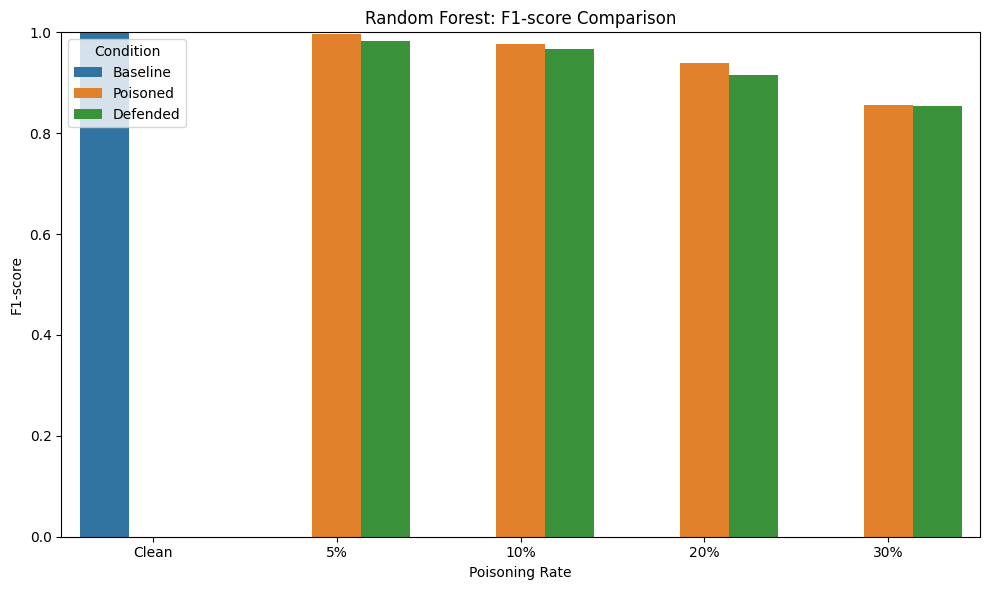

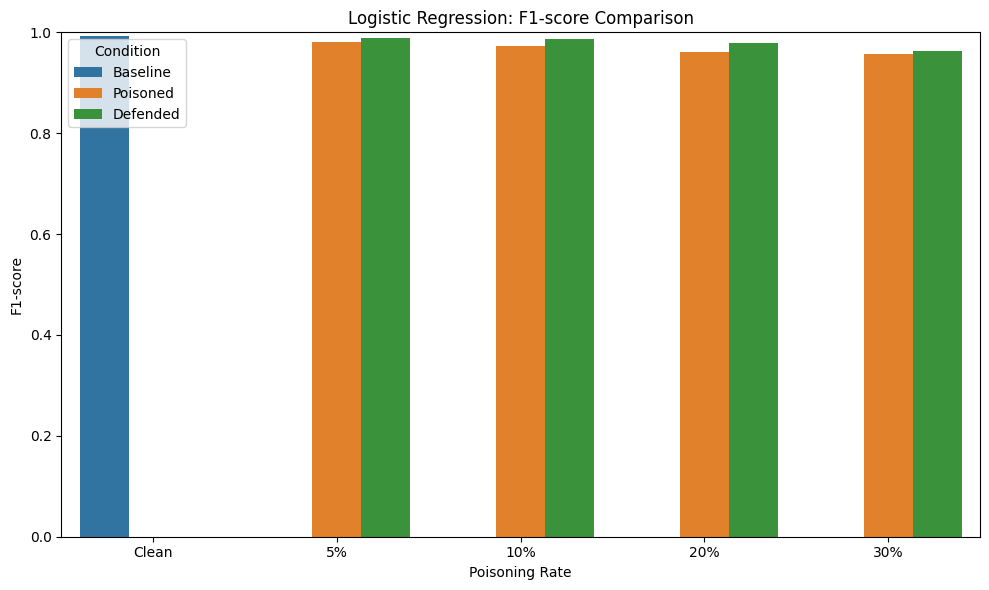

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Random Forest visualization
rf_comparison = comparison_df[
    comparison_df["Model"] == "Random Forest"
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_comparison,
    x="Poisoning Rate",
    y="F1-score",
    hue="Condition"
)

plt.title("Random Forest: F1-score Comparison")
plt.xlabel("Poisoning Rate")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


# Logistic Regression visualization
lr_comparison = comparison_df[
    comparison_df["Model"] == "Logistic Regression"
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=lr_comparison,
    x="Poisoning Rate",
    y="F1-score",
    hue="Condition"
)

plt.title("Logistic Regression: F1-score Comparison")
plt.xlabel("Poisoning Rate")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()

#**THRESHOLD EVALUATION: 0.70, 0.80, 0.90**

In [30]:
# ============================================================
# POISONGUARD: COMPLETE THRESHOLD EVALUATION
# Random Forest and Logistic Regression
# Thresholds: 0.70, 0.80, 0.90
# ============================================================

import numpy as np
import pandas as pd

thresholds = [0.70, 0.80, 0.90]

models_data = {
    "Random Forest": {
        "oof": rf_oof_results,
        "confidence": rf_confidence_results
    },

    "Logistic Regression": {
        "oof": lr_oof_results,
        "confidence": lr_confidence_results
    }
}

all_threshold_results = []

# Store suspicious indices for each model, rate and threshold
all_suspicious_indices = {}

# ============================================================
# STEP 1: IDENTIFY SUSPICIOUS RECORDS AT EACH THRESHOLD
# ============================================================

for model_name, model_data in models_data.items():

    all_suspicious_indices[model_name] = {}

    for rate in poisoning_rates:

        all_suspicious_indices[model_name][rate] = {}

        predictions = model_data["oof"][rate]["predictions"]

        confidence = model_data["confidence"][rate]

        y_poisoned = poisoned_datasets[rate].to_numpy()

        for threshold in thresholds:

            # Identify disagreements
            label_disagreement = y_poisoned != predictions

            # Identify high-confidence predictions
            high_confidence = confidence >= threshold

            # Suspicious records
            suspicious_mask = label_disagreement & high_confidence

            suspicious_indices = np.where(suspicious_mask)[0]

            all_suspicious_indices[model_name][rate][threshold] = (
                suspicious_indices
            )

            # =================================================
            # STEP 2: COMPARE WITH ACTUAL POISONED RECORDS
            # =================================================

            flipped = np.asarray(flipped_indices[rate])

            # Correctly detected poisoned records (TP)
            TP = len(np.intersect1d(
                suspicious_indices,
                flipped
            ))

            # Poisoned records not detected (FN)
            FN = len(np.setdiff1d(
                flipped,
                suspicious_indices
            ))

            # Legitimate records incorrectly removed (FP)
            FP = len(np.setdiff1d(
                suspicious_indices,
                flipped
            ))

            # Total records
            total_records = len(y_poisoned)

            # Total legitimate records
            total_legitimate = total_records - len(flipped)

            # Total suspicious records
            total_suspicious = len(suspicious_indices)

            # =================================================
            # STEP 3: CALCULATE METRICS
            # =================================================

            # Detection Rate
            detection_rate = (
                TP / len(flipped) * 100
                if len(flipped) > 0 else 0
            )

            # Detection Precision
            detection_precision = (
                TP / total_suspicious * 100
                if total_suspicious > 0 else 0
            )

            # Legitimate Removal Rate
            legitimate_removal_rate = (
                FP / total_legitimate * 100
                if total_legitimate > 0 else 0
            )

            # =================================================
            # STEP 4: SAVE RESULTS
            # =================================================

            all_threshold_results.append({

                "Model": model_name,

                "Poisoning Rate": rate,

                "Threshold": threshold,

                "Suspicious Records": total_suspicious,

                "Correctly Detected (TP)": TP,

                "Missed Poisoned (FN)": FN,

                "Legitimate Removed (FP)": FP,

                "Detection Rate (%)": round(
                    detection_rate, 4
                ),

                "Detection Precision (%)": round(
                    detection_precision, 4
                ),

                "Legitimate Removal Rate (%)": round(
                    legitimate_removal_rate, 4
                )
            })


# ============================================================
# STEP 5: DISPLAY COMPLETE RESULTS
# ============================================================

threshold_results_df = pd.DataFrame(all_threshold_results)

print("\n" + "=" * 90)
print("POISONGUARD THRESHOLD EVALUATION")
print("=" * 90)

display(threshold_results_df)


# ============================================================
# STEP 6: DISPLAY TABLE VII FORMAT
# ============================================================

table_vii = threshold_results_df[
    [
        "Model",
        "Threshold",
        "Suspicious Records",
        "Detection Rate (%)",
        "Detection Precision (%)",
        "Legitimate Removal Rate (%)"
    ]
]

print("\nTABLE VII: THRESHOLD COMPARISON")

display(table_vii)


# ============================================================
# STEP 7: SAVE RESULTS
# ============================================================

threshold_results_df.to_excel(
    "PoisonGuard_All_Threshold_Results.xlsx",
    index=False
)

table_vii.to_csv(
    "PoisonGuard_Table_VII.csv",
    index=False
)

print("\nResults exported successfully!")


POISONGUARD THRESHOLD EVALUATION


,Model,Poisoning Rate,Threshold,Suspicious Records,Correctly Detected (TP),Missed Poisoned (FN),Legitimate Removed (FP),Detection Rate (%),Detection Precision (%),Legitimate Removal Rate (%)
0,Random Forest,5%,0.7,12591,12361,2639,230,82.4067,98.1733,0.0807
1,Random Forest,5%,0.8,7883,7781,7219,102,51.8733,98.7061,0.0358
2,Random Forest,5%,0.9,3076,3036,11964,40,20.2400,98.6996,0.0140
3,Random Forest,10%,0.7,18845,18429,11571,416,61.4300,97.7925,0.1541
4,Random Forest,10%,0.8,9319,9231,20769,88,30.7700,99.0557,0.0326
5,Random Forest,10%,0.9,2646,2619,27381,27,8.7300,98.9796,0.0100
6,Random Forest,20%,0.7,19981,19209,40791,772,32.0150,96.1363,0.3217
7,Random Forest,20%,0.8,6696,6625,53375,71,11.0417,98.9397,0.0296
8,Random Forest,20%,0.9,821,818,59182,3,1.3633,99.6346,0.0013
9,Random Forest,30%,0.7,15383,14005,75995,1378,15.5611,91.0421,0.6562



TABLE VII: THRESHOLD COMPARISON


,Model,Threshold,Suspicious Records,Detection Rate (%),Detection Precision (%),Legitimate Removal Rate (%)
0,Random Forest,0.7,12591,82.4067,98.1733,0.0807
1,Random Forest,0.8,7883,51.8733,98.7061,0.0358
2,Random Forest,0.9,3076,20.2400,98.6996,0.0140
3,Random Forest,0.7,18845,61.4300,97.7925,0.1541
4,Random Forest,0.8,9319,30.7700,99.0557,0.0326
5,Random Forest,0.9,2646,8.7300,98.9796,0.0100
6,Random Forest,0.7,19981,32.0150,96.1363,0.3217
7,Random Forest,0.8,6696,11.0417,98.9397,0.0296
8,Random Forest,0.9,821,1.3633,99.6346,0.0013
9,Random Forest,0.7,15383,15.5611,91.0421,0.6562



Results exported successfully!


#**Develop the Streamlit Interface**

**Step 1 — Save the results**

In [31]:
comparison_df.to_csv("comparison_results.csv", index=False)

all_defended_results_df.to_csv("detection_results.csv", index=False)

print("Results files saved successfully.")

Results files saved successfully.


**Step 2 — Install Streamlit**

In [32]:
!pip install -q streamlit altair pandas

**Step 3 — Create app.py**

In [33]:
%%writefile app.py

import altair as alt
import pandas as pd
import streamlit as st

st.set_page_config(page_title="PoisonGuard", page_icon="🛡️", layout="wide")

# ---------------------------------------------------------------------------
# Results taken from the PoisonGuard_Defense notebook outputs
# ---------------------------------------------------------------------------
RATES = ["5%", "10%", "20%", "30%"]
METRICS = ["Accuracy", "Precision", "Recall", "F1-score", "False Positive Rate"]
CONDITIONS = ["Baseline", "Poisoned", "Defended"]
SAMPLE_SIZE = 300_000

DATASET = {
    "train_records": 7_160_831,
    "test_records": 1_614_182,
    "features_raw": 45,
    "features_used": 44,
    "train_benign": 192_732,
    "train_attack": 6_968_099,
    "test_benign": 37_607,
    "test_attack": 1_576_575,
    "sample_benign": 8_074,
    "sample_attack": 291_926,
}
FLIPPED = {"5%": 15_000, "10%": 30_000, "20%": 60_000, "30%": 90_000}
POISONED_DIST = {  # class distribution of the 300k sample after flipping
    "5%": (22_288, 277_712),
    "10%": (36_480, 263_520),
    "20%": (64_846, 235_154),
    "30%": (93_148, 206_852),
}

# (model, condition, rate): Accuracy, Precision, Recall, F1, FPR
_rows = [
    ("Random Forest", "Baseline", "Clean", 0.998266, 0.999291, 0.998933, 0.999112, 0.029702),
    ("Logistic Regression", "Baseline", "Clean", 0.985874, 0.999891, 0.985645, 0.992717, 0.004520),
    ("Random Forest", "Poisoned", "5%", 0.993308, 0.999068, 0.994076, 0.996566, 0.038876),
    ("Logistic Regression", "Poisoned", "5%", 0.961433, 0.999960, 0.960551, 0.979860, 0.001595),
    ("Random Forest", "Poisoned", "10%", 0.957512, 0.999114, 0.957347, 0.977785, 0.035578),
    ("Logistic Regression", "Poisoned", "10%", 0.948028, 0.999906, 0.946877, 0.972669, 0.003749),
    ("Random Forest", "Poisoned", "20%", 0.886989, 0.998856, 0.885308, 0.938660, 0.042519),
    ("Logistic Regression", "Poisoned", "20%", 0.927285, 0.998804, 0.926660, 0.961380, 0.046534),
    ("Random Forest", "Poisoned", "30%", 0.752844, 0.997969, 0.748472, 0.855399, 0.063871),
    ("Logistic Regression", "Poisoned", "30%", 0.918939, 0.999091, 0.917840, 0.956744, 0.034993),
    ("Random Forest", "Defended", "5%", 0.968308, 0.999450, 0.968085, 0.983517, 0.022336),
    ("Random Forest", "Defended", "10%", 0.938406, 0.999334, 0.937561, 0.967463, 0.026192),
    ("Random Forest", "Defended", "20%", 0.846637, 0.999215, 0.843641, 0.914861, 0.027787),
    ("Random Forest", "Defended", "30%", 0.751336, 0.998115, 0.746815, 0.854369, 0.059138),
    ("Logistic Regression", "Defended", "5%", 0.977815, 0.999981, 0.977305, 0.988513, 0.000798),
    ("Logistic Regression", "Defended", "10%", 0.972893, 0.999956, 0.972289, 0.985929, 0.001782),
    ("Logistic Regression", "Defended", "20%", 0.960482, 0.999912, 0.959624, 0.979354, 0.003537),
    ("Logistic Regression", "Defended", "30%", 0.931037, 0.998359, 0.930922, 0.963462, 0.064164),
]
RESULTS = pd.DataFrame(_rows, columns=["Model", "Condition", "Poisoning Rate"] + METRICS)

# (model, rate): detected, correctly detected
_det = {
    ("Random Forest", "5%"): (7883, 7781),
    ("Random Forest", "10%"): (9319, 9231),
    ("Random Forest", "20%"): (6696, 6625),
    ("Random Forest", "30%"): (3195, 3084),
    ("Logistic Regression", "5%"): (2812, 388),
    ("Logistic Regression", "10%"): (2582, 759),
    ("Logistic Regression", "20%"): (1868, 1254),
    ("Logistic Regression", "30%"): (855, 806),
}
DETECTION = pd.DataFrame(
    [
        {
            "Model": m,
            "Poisoning Rate": r,
            "Actual Flipped Records": FLIPPED[r],
            "Records Removed": d,
            "Correctly Detected": c,
            "Detection Rate": c / FLIPPED[r],
            "Detection Precision": c / d,
            "Records Remaining": SAMPLE_SIZE - d,
        }
        for (m, r), (d, c) in _det.items()
    ]
)

# Confidence-threshold comparison. (model, threshold): {rate: (suspicious, correctly detected)}
_thr_det = {
    ("Random Forest", 0.70): {"5%": (12591, 12361), "10%": (18845, 18429), "20%": (19981, 19209), "30%": (15383, 14005)},
    ("Random Forest", 0.80): {r: _det[("Random Forest", r)] for r in RATES},
    ("Random Forest", 0.90): {"5%": (3076, 3036), "10%": (2646, 2619), "20%": (821, 818), "30%": (167, 163)},
    ("Logistic Regression", 0.70): {"5%": (3651, 449), "10%": (3394, 808), "20%": (3333, 1541), "30%": (2598, 2010)},
    ("Logistic Regression", 0.80): {r: _det[("Logistic Regression", r)] for r in RATES},
    ("Logistic Regression", 0.90): {"5%": (1694, 347), "10%": (1142, 601), "20%": (676, 598), "30%": (44, 43)},
}
# Defended performance (percent) for 0.70 and 0.90: Accuracy, Precision, Recall, F1, FPR
_thr_perf = {
    ("Random Forest", 0.70): {"5%": (96.24, 99.97, 96.17, 98.04, 1.10), "10%": (92.03, 99.93, 91.91, 95.75, 2.85),
                              "20%": (81.22, 99.89, 80.86, 89.37, 3.74), "30%": (73.19, 99.82, 72.68, 84.12, 5.63)},
    ("Random Forest", 0.90): {"5%": (98.75, 99.91, 98.82, 99.36, 3.94), "10%": (95.47, 99.95, 95.41, 97.63, 1.86),
                              "20%": (87.57, 99.91, 87.36, 93.21, 3.44), "30%": (75.49, 99.79, 75.06, 85.68, 6.59)},
    ("Logistic Regression", 0.70): {"5%": (97.76, 100.00, 97.71, 98.84, 0.05), "10%": (97.25, 99.95, 97.23, 98.57, 1.92),
                                    "20%": (96.52, 99.88, 96.55, 98.19, 4.85), "30%": (94.47, 99.86, 94.47, 97.09, 5.52)},
    ("Logistic Regression", 0.90): {"5%": (97.87, 100.00, 97.82, 98.90, 0.13), "10%": (96.62, 99.99, 96.55, 98.24, 0.60),
                                    "20%": (94.23, 99.91, 94.17, 96.96, 3.37), "30%": (92.03, 99.90, 91.93, 95.75, 3.87)},
}
_perf_rows, _thr_rows = [], []
for (m, t), by_rate in _thr_det.items():
    for r, (d, c) in by_rate.items():
        _thr_rows.append({"Model": m, "Threshold": t, "Poisoning Rate": r, "Records Removed": d, "Correctly Detected": c,
                          "Detection Rate": c / FLIPPED[r], "Detection Precision": c / d})
        if t == 0.80:
            p = RESULTS[(RESULTS["Model"] == m) & (RESULTS["Condition"] == "Defended") & (RESULTS["Poisoning Rate"] == r)].iloc[0]
            vals = [p[k] for k in METRICS]
        else:
            vals = [v / 100 for v in _thr_perf[(m, t)][r]]
        _perf_rows.append({"Model": m, "Threshold": t, "Poisoning Rate": r, **dict(zip(METRICS, vals))})
THRESH_DET = pd.DataFrame(_thr_rows)
THRESH_PERF = pd.DataFrame(_perf_rows)
THRESHOLDS = [0.70, 0.80, 0.90]

# ---------------------------------------------------------------------------
# Styling (light cybersecurity dashboard)
# ---------------------------------------------------------------------------
NAVY, BLUE, TEAL, RED, AMBER, GREY = "#0B2545", "#1F6FEB", "#0E9F8E", "#D64545", "#E08A00", "#6B7A90"
COND_COLORS = alt.Scale(domain=CONDITIONS, range=[TEAL, RED, BLUE])

st.markdown(
    f"""
<style>
.stApp {{ background-color: #F5F7FB; color: #1B2A41; }}
[data-testid="stSidebar"] {{ background-color: #FFFFFF; border-right: 1px solid #E3E8F0; }}
.block-container {{ padding-top: 1.5rem; max-width: 1250px; }}
h1, h2, h3 {{ color: {NAVY}; }}
.hero {{ background: linear-gradient(120deg, {NAVY} 0%, #1F4E9C 100%); color: #fff;
        padding: 26px 30px; border-radius: 14px; margin-bottom: 22px; }}
.hero h1 {{ color: #fff; margin: 0 0 4px 0; font-size: 2.1rem; }}
.hero p {{ color: #D7E3F7; margin: 0; font-size: 1.02rem; }}
.card {{ background: #fff; border: 1px solid #E3E8F0; border-radius: 12px; padding: 18px 20px;
        box-shadow: 0 1px 3px rgba(11,37,69,.05); height: 100%; }}
.card h4 {{ margin: 0 0 8px 0; color: {NAVY}; font-size: 1rem; }}
.card ul {{ margin: 0; padding-left: 18px; }}
.tag {{ display:inline-block; background:#E8F0FE; color:{BLUE}; border-radius: 20px;
       padding: 3px 12px; margin: 2px 4px 2px 0; font-size: .85rem; font-weight: 600; }}
.step {{ background:#fff; border:1px solid #E3E8F0; border-left: 5px solid {BLUE}; border-radius: 10px;
        padding: 14px 18px; margin-bottom: 10px; }}
.step b {{ color: {NAVY}; }}
.step .n {{ display:inline-block; background:{BLUE}; color:#fff; width:28px; height:28px; line-height:28px;
           text-align:center; border-radius:50%; margin-right:10px; font-weight:700; }}
[data-testid="stMetric"] {{ background:#fff; border:1px solid #E3E8F0; border-radius:12px; padding:14px 16px; }}
</style>
""",
    unsafe_allow_html=True,
)


def hero(title, subtitle):
    st.markdown(f'<div class="hero"><h1>🛡️ {title}</h1><p>{subtitle}</p></div>', unsafe_allow_html=True)


def card(title, items=None, body=None):
    inner = body or "<ul>" + "".join(f"<li>{i}</li>" for i in items) + "</ul>"
    st.markdown(f'<div class="card"><h4>{title}</h4>{inner}</div>', unsafe_allow_html=True)


def style_chart(chart):
    return (
        chart.configure_view(strokeWidth=0)
        .configure_axis(labelColor="#1B2A41", titleColor="#1B2A41", gridColor="#E8ECF3")
        .configure_legend(labelColor="#1B2A41", titleColor="#1B2A41")
    )


# ---------------------------------------------------------------------------
# Sidebar
# ---------------------------------------------------------------------------
st.sidebar.markdown("## 🛡️ PoisonGuard")
st.sidebar.caption("Data Poisoning Defense for IDS")
page = st.sidebar.radio(
    "Navigation",
    [
        "1 · Project Overview",
        "2 · Dataset & Poisoning",
        "3 · Model Performance",
        "4 · Detection Results",
        "5 · Defense Workflow",
        "6 · Threshold Comparison",
    ],
)
st.sidebar.divider()
st.sidebar.caption("Dataset: CICIoMT2024 (WiFi & MQTT)")
st.sidebar.caption("Special Topics in Cybersecurity")

# ---------------------------------------------------------------------------
# 1. Project Overview
# ---------------------------------------------------------------------------
if page.startswith("1"):
    hero("PoisonGuard", "ML-Based Data Poisoning Defense for Intrusion Detection Systems")
    st.header("Project Overview")
    st.write(
        "PoisonGuard is a machine learning-based defense system designed to detect and mitigate data "
        "poisoning attacks against Intrusion Detection Systems (IDS). The project investigates how "
        "label-flipping attacks affect the performance of machine learning models and evaluates a defense "
        "mechanism that identifies suspicious training records using out-of-fold predictions and prediction confidence."
    )

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Dataset", "CICIoMT2024")
    c2.metric("Models", "2")
    c3.metric("Attack", "Label Flipping")
    c4.metric("Defense", "OOF Detection")
    st.write("")

    a, b = st.columns(2)
    with a:
        card(
            "Objectives",
            [
                "Train machine learning models to detect network intrusions.",
                "Simulate label-flipping attacks at different poisoning rates.",
                "Identify suspicious and potentially poisoned training records.",
                "Remove suspicious records and retrain the models.",
                "Evaluate the effectiveness of the defense using an untouched test dataset.",
            ],
        )
    with b:
        card(
            "Dataset",
            body="<b>CICIoMT2024</b> – A network traffic dataset containing benign and malicious traffic "
            "from Internet of Medical Things (IoMT) environments.",
        )
        st.write("")
        card(
            "Machine Learning Models",
            body='<span class="tag">Random Forest</span><span class="tag">Logistic Regression</span>',
        )
    st.write("")
    a, b = st.columns(2)
    with a:
        card(
            "Attack Simulation",
            body="Label-flipping poisoning is tested at four rates:<br>"
            + "".join(f'<span class="tag">{r}</span>' for r in RATES),
        )
    with b:
        card(
            "Defense Methodology",
            body="PoisonGuard uses a five-fold cross-validation approach to generate out-of-fold predictions. "
            "It compares model predictions against the provided training labels and uses prediction confidence "
            "to identify suspicious records. The identified records are removed before retraining the models.",
        )
    st.write("")
    a, b = st.columns(2)
    with a:
        card("Evaluation Metrics", METRICS + ["Poisoned-record Detection Rate", "Detection Precision"])
    with b:
        card(
            "Expected Outcome",
            body="Evaluate whether PoisonGuard can reduce the impact of label-flipping attacks, improve IDS "
            "reliability, and identify suspicious training records while maintaining strong detection performance.",
        )

# ---------------------------------------------------------------------------
# 2. Dataset & Poisoning
# ---------------------------------------------------------------------------
elif page.startswith("2"):
    hero("Dataset & Poisoning Configuration", "The 300,000-record training sample, before and after label flipping")
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Training sample", f"{SAMPLE_SIZE:,}", help="Stratified sample used to train every model")
    c2.metric("Benign / Attack", f"{DATASET['sample_benign']:,} / {DATASET['sample_attack']:,}", help="Before poisoning")
    c3.metric("Features", DATASET["features_used"], help="Constant feature 'Drate' removed")
    c4.metric("Test set", f"{DATASET['test_records']:,}", help="Full untouched test set, used for all metrics")

    FLIP_B2A = {"5%": 393, "10%": 797, "20%": 1614, "30%": 2463}  # derived from class counts
    rows = [("Clean (before attack)", DATASET["sample_benign"], DATASET["sample_attack"], 0, 0)]
    for r in RATES:
        rows.append((f"{r} poisoned", POISONED_DIST[r][0], POISONED_DIST[r][1], FLIP_B2A[r], FLIPPED[r] - FLIP_B2A[r]))
    dist = pd.DataFrame(rows, columns=["Condition", "Benign", "Attack", "Benign→Attack", "Attack→Benign"])
    dist["Total"] = dist["Benign"] + dist["Attack"]
    dist["Benign share"] = dist["Benign"] / dist["Total"]

    st.subheader("Class distribution before and after poisoning")
    left, right = st.columns([3, 2])
    with left:
        long = dist.melt(id_vars="Condition", value_vars=["Benign", "Attack"], var_name="Class", value_name="Records")
        long["Share"] = long["Records"] / SAMPLE_SIZE
        ch = (
            alt.Chart(long)
            .mark_bar()
            .encode(
                x=alt.X("Condition:N", sort=list(dist["Condition"]), title=None, axis=alt.Axis(labelAngle=0, labelLimit=120)),
                y=alt.Y("Share:Q", title="Share of the 300,000 sample", axis=alt.Axis(format="%")),
                color=alt.Color("Class:N", scale=alt.Scale(domain=["Benign", "Attack"], range=[TEAL, RED])),
                tooltip=["Condition", "Class", alt.Tooltip("Records:Q", format=",")],
            )
            .properties(height=300)
        )
        st.altair_chart(style_chart(ch), width="stretch")
    with right:
        show = dist[["Condition", "Benign", "Attack"]].copy()
        show["Benign"] = show["Benign"].map("{:,}".format)
        show["Attack"] = show["Attack"].map("{:,}".format)
        show["Benign share"] = (dist["Benign share"] * 100).map("{:.2f}%".format)
        st.dataframe(show, width="stretch", hide_index=True)
    st.info(f"Every row adds up to {SAMPLE_SIZE:,}. Attack is 97.31% of the clean sample, so flipping moves far more attack records to benign than the reverse.")

    st.subheader("Poisoning configuration")
    cfg = pd.DataFrame(
        {
            "Poisoning Rate": RATES,
            "Labels Flipped": [FLIPPED[r] for r in RATES],
            "Benign → Attack": [FLIP_B2A[r] for r in RATES],
            "Attack → Benign": [FLIPPED[r] - FLIP_B2A[r] for r in RATES],
        }
    )
    left, right = st.columns([3, 2])
    with left:
        ch = (
            alt.Chart(cfg)
            .mark_bar(color=RED)
            .encode(
                x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
                y=alt.Y("Labels Flipped:Q"),
                tooltip=["Poisoning Rate", alt.Tooltip("Labels Flipped:Q", format=",")],
            )
            .properties(height=280, title="Labels flipped per poisoning rate")
        )
        text = ch.mark_text(dy=-8, color=NAVY).encode(text=alt.Text("Labels Flipped:Q", format=","))
        st.altair_chart(style_chart(ch + text), width="stretch")
    with right:
        st.dataframe(cfg.style.format({c: "{:,}" for c in cfg.columns[1:]}), width="stretch", hide_index=True)
        st.caption("Records are picked at random from the sample (seed 42). The direction split is worked out from the class counts.")

# ---------------------------------------------------------------------------
# 3. Model Performance
# ---------------------------------------------------------------------------
elif page.startswith("3"):
    hero("Model Performance", "Baseline vs. poisoned vs. defended, evaluated on the untouched test set")
    c1, c2 = st.columns(2)
    model = c1.selectbox("Model", ["Random Forest", "Logistic Regression"])
    rate = c2.select_slider("Poisoning rate", options=RATES, value="10%")

    md = RESULTS[RESULTS["Model"] == model]
    base = md[md["Condition"] == "Baseline"].iloc[0]
    pois = md[(md["Condition"] == "Poisoned") & (md["Poisoning Rate"] == rate)].iloc[0]
    defd = md[(md["Condition"] == "Defended") & (md["Poisoning Rate"] == rate)].iloc[0]

    st.subheader(f"{model} — {rate} poisoning")
    table = pd.DataFrame(
        {"Metric": METRICS, "Baseline": [base[m] for m in METRICS], "Poisoned": [pois[m] for m in METRICS], "Defended": [defd[m] for m in METRICS]}
    )
    table["Defended − Poisoned"] = table["Defended"] - table["Poisoned"]
    st.dataframe(
        table.style.format({c: "{:.4f}" for c in table.columns[1:]}),
        width="stretch",
        hide_index=True,
    )
    st.caption("For False Positive Rate, lower is better. For all other metrics, higher is better.")

    k1, k2, k3 = st.columns(3)
    k1.metric("F1 · Baseline", f"{base['F1-score']:.4f}")
    k2.metric("F1 · Poisoned", f"{pois['F1-score']:.4f}", f"{pois['F1-score'] - base['F1-score']:+.4f}", delta_color="normal")
    k3.metric("F1 · Defended", f"{defd['F1-score']:.4f}", f"{defd['F1-score'] - pois['F1-score']:+.4f} vs poisoned")

    st.subheader("Impact as the poisoning rate increases")
    metric = st.selectbox("Metric", METRICS, index=3)
    rows = []
    for r in RATES:
        rows.append({"Poisoning Rate": r, "Condition": "Baseline", "Value": base[metric]})
        for cond in ["Poisoned", "Defended"]:
            v = md[(md["Condition"] == cond) & (md["Poisoning Rate"] == r)].iloc[0][metric]
            rows.append({"Poisoning Rate": r, "Condition": cond, "Value": v})
    chart_df = pd.DataFrame(rows)
    line = (
        alt.Chart(chart_df)
        .mark_line(point=alt.OverlayMarkDef(size=70), strokeWidth=3)
        .encode(
            x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
            y=alt.Y("Value:Q", title=metric, scale=alt.Scale(zero=False)),
            color=alt.Color("Condition:N", scale=COND_COLORS),
            tooltip=["Poisoning Rate", "Condition", alt.Tooltip("Value:Q", format=".4f")],
        )
        .properties(height=340, title=f"{model}: {metric}")
    )
    st.altair_chart(style_chart(line), width="stretch")

    st.subheader("Grouped comparison across all rates")
    grp = (
        alt.Chart(chart_df)
        .mark_bar()
        .encode(
            x=alt.X("Condition:N", sort=CONDITIONS, title=None, axis=alt.Axis(labels=False)),
            y=alt.Y("Value:Q", title=metric),
            color=alt.Color("Condition:N", scale=COND_COLORS),
            column=alt.Column("Poisoning Rate:N", sort=RATES, title=None),
            tooltip=["Poisoning Rate", "Condition", alt.Tooltip("Value:Q", format=".4f")],
        )
        .properties(width=150, height=240)
    )
    st.altair_chart(style_chart(grp))

    st.subheader("Defense effect summary (Defended − Poisoned)")
    eff = []
    for r in RATES:
        p = md[(md["Condition"] == "Poisoned") & (md["Poisoning Rate"] == r)].iloc[0]
        d = md[(md["Condition"] == "Defended") & (md["Poisoning Rate"] == r)].iloc[0]
        eff.append({"Poisoning Rate": r, **{m: d[m] - p[m] for m in METRICS}})
    eff = pd.DataFrame(eff)
    st.dataframe(eff.style.format({m: "{:+.4f}" for m in METRICS}), width="stretch", hide_index=True)
    better = (eff["F1-score"] > 0).sum()
    st.info(
        f"For {model}, the defense improved F1-score at {better} of 4 poisoning rates, "
        f"and lowered the false positive rate at {(eff['False Positive Rate'] < 0).sum()} of 4."
    )

# ---------------------------------------------------------------------------
# 4. Detection Results
# ---------------------------------------------------------------------------
elif page.startswith("4"):
    hero("PoisonGuard Detection Results", "How well suspicious records match the labels that were actually flipped")
    model = st.selectbox("Model", ["Random Forest", "Logistic Regression"])
    det = DETECTION[DETECTION["Model"] == model].set_index("Poisoning Rate").loc[RATES].reset_index()

    rate = st.select_slider("Poisoning rate", options=RATES, value="5%")
    row = det[det["Poisoning Rate"] == rate].iloc[0]
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Detection Rate", f"{row['Detection Rate']:.2%}", help="Share of actual poisoned records detected")
    c2.metric("Detection Precision", f"{row['Detection Precision']:.2%}", help="Share of flagged records that were truly poisoned")
    c3.metric("Records Removed", f"{int(row['Records Removed']):,}")
    c4.metric("Records Remaining", f"{int(row['Records Remaining']):,}")

    st.subheader("All poisoning rates")
    table = det[["Poisoning Rate", "Actual Flipped Records", "Records Removed", "Correctly Detected", "Detection Rate", "Detection Precision", "Records Remaining"]]
    st.dataframe(
        table.style.format(
            {
                "Actual Flipped Records": "{:,}", "Records Removed": "{:,}", "Correctly Detected": "{:,}",
                "Records Remaining": "{:,}", "Detection Rate": "{:.2%}", "Detection Precision": "{:.2%}",
            }
        ),
        width="stretch",
        hide_index=True,
    )

    left, right = st.columns(2)
    long = det.melt(id_vars="Poisoning Rate", value_vars=["Detection Rate", "Detection Precision"], var_name="Metric", value_name="Value")
    with left:
        ch = (
            alt.Chart(long)
            .mark_bar()
            .encode(
                x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
                xOffset="Metric:N",
                y=alt.Y("Value:Q", axis=alt.Axis(format="%"), scale=alt.Scale(domain=[0, 1])),
                color=alt.Color("Metric:N", scale=alt.Scale(range=[BLUE, TEAL])),
                tooltip=["Poisoning Rate", "Metric", alt.Tooltip("Value:Q", format=".2%")],
            )
            .properties(height=320, title="Detection Rate vs. Detection Precision")
        )
        st.altair_chart(style_chart(ch), width="stretch")
    with right:
        cnt = det.melt(id_vars="Poisoning Rate", value_vars=["Actual Flipped Records", "Records Removed", "Correctly Detected"], var_name="Count", value_name="Records")
        ch = (
            alt.Chart(cnt)
            .mark_bar()
            .encode(
                x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
                xOffset="Count:N",
                y=alt.Y("Records:Q"),
                color=alt.Color("Count:N", scale=alt.Scale(range=[RED, AMBER, TEAL])),
                tooltip=["Poisoning Rate", "Count", alt.Tooltip("Records:Q", format=",")],
            )
            .properties(height=320, title="Flipped vs. flagged vs. correctly flagged")
        )
        st.altair_chart(style_chart(ch), width="stretch")

    st.info(
        "Detection uses a 0.80 confidence threshold: a record is flagged only when the out-of-fold prediction "
        "disagrees with its stored label with ≥80% confidence. Higher poisoning rates lower model confidence, "
        "so fewer records pass the threshold and the detection rate falls."
    )

# ---------------------------------------------------------------------------
# 5. Defense Workflow
# ---------------------------------------------------------------------------
elif page.startswith("5"):
    hero("Defense Workflow", "How PoisonGuard detects and removes poisoned training records")
    steps = [
        ("Load the training dataset", "CICIoMT2024 WiFi/MQTT data; labels converted to Benign (0) / Attack (1); a 300,000-record stratified sample is used."),
        ("Apply label-flipping poisoning", "Randomly flip 5%, 10%, 20% and 30% of the training labels (Benign ↔ Attack)."),
        ("Generate OOF predictions", "5-fold stratified cross-validation: every record is predicted by a model that never saw it."),
        ("Calculate prediction confidence", "Confidence = highest predicted class probability for each record."),
        ("Identify suspicious records", "Flag records whose OOF prediction disagrees with the stored label at confidence ≥ 0.80."),
        ("Remove suspicious records", "Drop the flagged records from the (poisoned) training set."),
        ("Retrain the models", "Fit fresh Random Forest and Logistic Regression models on the cleaned data."),
        ("Evaluate the defended models", "Measure Accuracy, Precision, Recall, F1-score and FPR on the untouched test set; compare with baseline and poisoned models."),
    ]
    left, right = st.columns([3, 2])
    with left:
        for i, (t, d) in enumerate(steps, 1):
            st.markdown(f'<div class="step"><span class="n">{i}</span><b>{t}</b><br><span style="color:{GREY}">{d}</span></div>', unsafe_allow_html=True)
    with right:
        st.markdown(
            f"""
<div class="card"><h4>Detection rule</h4>
<p style="color:{GREY};margin:0 0 10px 0">A training record is <b>suspicious</b> when both hold:</p>
<div class="step" style="border-left-color:{RED}"><b>Label disagreement</b><br>OOF prediction ≠ stored label</div>
<div class="step" style="border-left-color:{AMBER}"><b>High confidence</b><br>max class probability ≥ 0.80</div>
<p style="color:{GREY};margin:10px 0 0 0">Suspicious = disagreement <b>AND</b> high confidence.</p>
</div>
""",
            unsafe_allow_html=True,
        )
        st.write("")
        card("Configuration", ["Folds: 5 (stratified, seed 42)", "Confidence threshold: 0.80", "RF: 100 trees, min_samples_leaf=2, balanced weights", "LR: balanced weights, max_iter=300", "Sample size: 300,000 records"])


# ---------------------------------------------------------------------------
# 6. Threshold Comparison
# ---------------------------------------------------------------------------
else:
    hero("Confidence Threshold Comparison", "How the 0.70, 0.80 and 0.90 thresholds change what PoisonGuard flags")
    st.write(
        "PoisonGuard uses a confidence threshold to decide whether a record should be flagged as suspicious. "
        "A lower threshold (0.70) allows more records to be flagged, increasing the number of potentially poisoned "
        "records detected. However, it may also flag more legitimate records. A higher threshold (0.90) applies "
        "stricter detection criteria. It generally improves detection precision but reduces the number of "
        "suspicious records identified."
    )
    model = st.selectbox("Model", ["Random Forest", "Logistic Regression"])
    td = THRESH_DET[THRESH_DET["Model"] == model].copy()
    tp = THRESH_PERF[THRESH_PERF["Model"] == model].copy()
    td["Threshold"] = td["Threshold"].map("{:.2f}".format)
    tp["Threshold"] = tp["Threshold"].map("{:.2f}".format)
    TH_COLORS = alt.Scale(domain=["0.70", "0.80", "0.90"], range=[AMBER, BLUE, TEAL])

    st.subheader(f"{model}: suspicious record detection")
    st.dataframe(
        td[["Threshold", "Poisoning Rate", "Records Removed", "Correctly Detected", "Detection Rate", "Detection Precision"]]
        .style.format({"Records Removed": "{:,}", "Correctly Detected": "{:,}", "Detection Rate": "{:.2%}", "Detection Precision": "{:.2%}"}),
        width="stretch", hide_index=True,
    )

    left, right = st.columns(2)
    for col, metric in ((left, "Detection Rate"), (right, "Detection Precision")):
        with col:
            ch = (
                alt.Chart(td)
                .mark_bar()
                .encode(
                    x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
                    xOffset="Threshold:N",
                    y=alt.Y(f"{metric}:Q", axis=alt.Axis(format="%"), scale=alt.Scale(domain=[0, 1])),
                    color=alt.Color("Threshold:N", scale=TH_COLORS),
                    tooltip=["Threshold", "Poisoning Rate", alt.Tooltip(f"{metric}:Q", format=".2%")],
                )
                .properties(height=300, title=metric)
            )
            st.altair_chart(style_chart(ch), width="stretch")

    st.subheader(f"Defended {model} performance")
    perf_metric = st.selectbox("Metric", METRICS, index=3)
    left, right = st.columns([2, 3])
    with left:
        piv = tp.pivot(index="Poisoning Rate", columns="Threshold", values=perf_metric).loc[RATES].reset_index()
        st.dataframe(piv.style.format({c: "{:.2%}" for c in piv.columns[1:]}), width="stretch", hide_index=True)
    with right:
        ch = (
            alt.Chart(tp)
            .mark_line(point=alt.OverlayMarkDef(size=70), strokeWidth=3)
            .encode(
                x=alt.X("Poisoning Rate:N", sort=RATES, axis=alt.Axis(labelAngle=0)),
                y=alt.Y(f"{perf_metric}:Q", title=perf_metric, scale=alt.Scale(zero=False), axis=alt.Axis(format="%")),
                color=alt.Color("Threshold:N", scale=TH_COLORS),
                tooltip=["Threshold", "Poisoning Rate", alt.Tooltip(f"{perf_metric}:Q", format=".2%")],
            )
            .properties(height=280, title=f"{model}: {perf_metric}")
        )
        st.altair_chart(style_chart(ch), width="stretch")

    st.subheader("Key Observations")
    st.markdown(
        """
- **Random Forest (0.70):** Detected more potentially poisoned records, achieving higher detection rates across all poisoning levels.
- **Random Forest (0.90):** Achieved higher detection precision but detected considerably fewer poisoned records.
- **Logistic Regression (0.70):** Showed relatively low detection precision, particularly at lower poisoning rates.
- **Logistic Regression (0.90):** Improved detection precision at higher poisoning rates, but its detection rate remained very low.
"""
    )
    st.subheader("Conclusion")
    st.info(
        "The confidence threshold involves a trade-off between detecting more poisoned records and avoiding false alarms. "
        "A lower threshold is more suitable when detecting as many potentially poisoned records as possible, "
        "while a higher threshold is more conservative."
    )


Writing app.py


In [34]:
!ls -l app.py
!python -m py_compile app.py && echo "app.py OK"

-rw-r--r-- 1 root root 31082 Nov 19 20:54 app.py
app.py OK


**Step 4 — Run the application**

In [35]:
!streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &

In [36]:
!sleep 6; cat /content/logs.txt



2026-11-19 20:54:49.166 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.90.55.112:8501



In [37]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [38]:
!./cloudflared tunnel --url http://localhost:8501

2026-11-19T20:55:00Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-19T20:55:00Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-19T20:55:05Z INF +--------------------------------------------------------------------------------------------+
2026-11-19T20:55:05Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-19T20:55:05Z INF |  https://rubber-yukon-contest-economic.trycloudflare.c